# Clasificación de intención de atención

El servicio actual convierte una nota de ticket en una de cinco intenciones. Este experimento reproduce el resultado de la regresión logística de referencia, compara alternativas y verifica si la mejora se transfiere al primer motivo expresado por un cliente.

- **Entrenamiento y ranking.** Se usan los tickets sintéticos entregados para la prueba. La entrada es `descripcion` y el objetivo es `categoria`. La clase `cancelacion` representa la intención expresada durante la atención. El riesgo futuro de baja tiene su propio objetivo, `churn_90d`, en `clientes_churn.csv`.
- **Métrica principal.** F1 macro calculado sobre predicciones fuera de muestra, con el mismo peso para las cinco clases. El desempate usa recall y luego precisión de cancelación. La meta de referencia de la prueba es 0,80 de F1. El recall de cancelación también se revisa por separado por su impacto en retención.
- **Transferencia.** Las transcripciones sintéticas se evalúan después de elegir el candidato con tickets. Los modelos se ajustan en CPU. El experimento trabaja en memoria y el único acceso externo es para descargar los pesos públicos del codificador E5.

## Ejecución

Desde la raíz de `claro-copilot`, ejecute el notebook con el entorno bloqueado del servicio y las dependencias adicionales del experimento.

```bash
uv run --project services/ml --frozen --python 3.12 \
  --with ipykernel==6.29.5 --with nbclient==0.10.2 \
  --with matplotlib==3.10.0 --with onnxruntime==1.23.2 \
  --with tokenizers==0.22.2 --with huggingface-hub==0.36.0 \
  jupyter-execute --inplace --timeout=300 services/ml/notebooks/comparacion_intencion.ipynb
```

Para usar Jupyter, abra este archivo con un kernel que tenga las mismas dependencias y ejecute todas las celdas. La carpeta `Insumos_Prueba_Consultor_IA` se busca al ascender desde el directorio de trabajo. Puede indicar otra ubicación con `CLARO_INSUMOS_DIR`. Hugging Face guarda en caché la revisión fijada de E5 (aproximadamente 470 MB). Las salidas muestran métricas y agregados, sin textos de tickets ni transcripciones.

In [1]:
import os
import re
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import Markdown, display
from matplotlib.ticker import PercentFormatter
from scipy.optimize import OptimizeWarning
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.naive_bayes import ComplementNB
from sklearn.pipeline import FeatureUnion, make_pipeline
from sklearn.svm import LinearSVC
from threadpoolctl import threadpool_limits

ancestors = (Path.cwd(), *Path.cwd().parents)
root = next((path for path in ancestors if (path / "services/ml/app/train.py").is_file()), None)
if root is None:
    raise FileNotFoundError("Ejecute el notebook desde el repositorio claro-copilot.")
insumos_override = os.getenv("CLARO_INSUMOS_DIR")
if insumos_override:
    insumos = Path(insumos_override).expanduser()
else:
    insumos = next(
        (path / "Insumos_Prueba_Consultor_IA" for path in ancestors
         if (path / "Insumos_Prueba_Consultor_IA").is_dir()),
        root.parent / "Insumos_Prueba_Consultor_IA",
    )
tickets_path = insumos / "03_datos/tickets.csv"
if not tickets_path.is_file():
    raise FileNotFoundError("Configure CLARO_INSUMOS_DIR con la ruta a los insumos de la prueba.")

sys.path.insert(0, str(root / "services/ml"))
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
# En ejecución sin widgets, tqdm usa la salida de texto.
warnings.filterwarnings("ignore", message=r"IProgress not found\.", module=r"tqdm\.auto")
# El scikit-learn del servicio aún pasa iprint, una opción de salida ya retirada de SciPy.
warnings.filterwarnings(
    "ignore", message=r"Unknown solver options: iprint$", category=OptimizeWarning,
    module=r"sklearn\.linear_model\._logistic",
)
from app.common import LABELS, digest, group, normalize
from app.train import pipeline as deployed_pipeline

labels = sorted(LABELS)
seed = 42
target_f1 = 0.80
plt.rcParams.update({"figure.dpi": 125, "axes.spines.top": False, "axes.spines.right": False})
print(f"Python {sys.version.split()[0]} · scikit-learn {sklearn.__version__} · pandas {pd.__version__}")
print(f"SHA-256 de tickets.csv  {digest(tickets_path.read_bytes())}")

Python 3.12.14 · scikit-learn 1.6.1 · pandas 2.2.3
SHA-256 de tickets.csv  c922f1984c060433d74daf561289e88a1d82151c403461614ec5e991a2a27d96


## Qué limpieza aplica el entrenamiento

Se replica el orden de `app.train`. Léase todo como texto, elimínense filas idénticas y normalícense las etiquetas con minúsculas y recorte de espacios. `app.common.normalize` homogeneiza Unicode NFKC, mayúsculas y espacios, y enmascara correos y secuencias largas de tipo teléfono o identificación. Los códigos cortos se conservan en la entrada. Para dividir los datos se construye una clave adicional que reemplaza secuencias de dígitos, así las variantes de una plantilla quedan en el mismo bloque.

Se comprueban las cinco etiquetas y las descripciones no vacías. Los grupos con varias etiquetas se conservan para evaluar las ambigüedades presentes en los insumos. Algunas categorías perderían todo su soporte si se eliminaran esos grupos. La satisfacción, los tiempos de resolución, el canal, los identificadores y las demás columnas quedan fuera de los predictores.

In [2]:
raw = pd.read_csv(tickets_path, dtype=str).fillna("")
tickets = raw.drop_duplicates().reset_index(drop=True)
tickets["texto"] = tickets["descripcion"].map(normalize)
tickets["categoria"] = tickets["categoria"].str.strip().str.lower()
assert set(tickets["categoria"]) == LABELS and tickets["texto"].ne("").all()
tickets["plantilla"] = tickets["texto"].map(group)

mixed_text = tickets.groupby("texto")["categoria"].transform("nunique").gt(1)
mixed_group = tickets.groupby("plantilla")["categoria"].transform("nunique").gt(1)
period = pd.to_datetime(tickets["fecha_creacion"])

audit = pd.Series({
    "Filas entregadas": len(raw),
    "Duplicados exactos eliminados": len(raw) - len(tickets),
    "Filas usadas": len(tickets),
    "Inicio de los tickets": period.min().date().isoformat(),
    "Fin de los tickets": period.max().date().isoformat(),
    "Descripciones originales distintas": tickets["descripcion"].nunique(),
    "Descripciones normalizadas distintas": tickets["texto"].nunique(),
    "Plantillas": tickets["plantilla"].nunique(),
    "Textos normalizados con varias etiquetas": tickets.loc[mixed_text, "texto"].nunique(),
    "Filas con un texto de varias etiquetas": int(mixed_text.sum()),
    "Plantillas con varias etiquetas": tickets.loc[mixed_group, "plantilla"].nunique(),
    "Filas de plantillas con varias etiquetas": int(mixed_group.sum()),
    "Valores de satisfacción vacíos en el original": int(raw["satisfaccion"].eq("").sum()),
}, name="Valor")
display(audit.to_frame())
display(tickets.assign(texto_en_conflicto=mixed_text).groupby("categoria").agg(
    filas=("texto", "size"),
    plantillas=("plantilla", "nunique"),
    filas_con_texto_en_conflicto=("texto_en_conflicto", "sum"),
))

,Valor
Filas entregadas,3816
Duplicados exactos eliminados,20
Filas usadas,3796
Inicio de los tickets,2025-11-01
Fin de los tickets,2026-10-31
Descripciones originales distintas,164
Descripciones normalizadas distintas,164
Plantillas,40
Textos normalizados con varias etiquetas,42
Filas con un texto de varias etiquetas,3169


,filas,plantillas,filas_con_texto_en_conflicto
categoria,,,
cancelacion,368,26,368
consulta_planes,534,22,533
facturacion,1055,28,873
portabilidad,276,13,234
soporte_tecnico,1563,28,1161


## Particiones agrupadas

Se reproduce el criterio del entrenamiento con `StratifiedGroupKFold`, semilla 42 y búsqueda de cinco a dos particiones. Se elige el mayor número que conserva todas las clases en cada conjunto de entrenamiento y prueba. El vocabulario, la ponderación TF-IDF y los clasificadores se ajustan dentro de cada partición. Se comprueba que cada fila se prediga exactamente una vez y que el conjunto de plantillas de prueba sea disjunto del de entrenamiento.

También se informa cuántos clientes aparecen en ambos lados. El diseño mide generalización a **plantillas nuevas**. Para afirmar generalización simultánea a clientes nuevos haría falta otra partición. El identificador de cliente no entra al modelo. [Documentación de particiones agrupadas](https://scikit-learn.org/1.6/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html)

In [3]:
def make_folds(frame, max_folds=5):
    for count in range(max_folds, 1, -1):
        cv = StratifiedGroupKFold(n_splits=count, shuffle=True, random_state=seed)
        splits = list(cv.split(frame["texto"], frame["categoria"], frame["plantilla"]))
        if all(set(frame["categoria"].iloc[index]) == LABELS
               for fold in splits for index in fold):
            covered = np.concatenate([test for _, test in splits])
            assert np.array_equal(np.sort(covered), np.arange(len(frame)))
            for train, test in splits:
                assert set(frame["plantilla"].iloc[train]).isdisjoint(frame["plantilla"].iloc[test])
            return splits
    raise ValueError("No hay particiones agrupadas con cobertura de las cinco clases.")

folds = make_folds(tickets)
fold_audit = pd.DataFrame([
    {
        "Partición": number,
        "Tickets de entrenamiento": len(train),
        "Tickets de prueba": len(test),
        "Plantillas de prueba": tickets["plantilla"].iloc[test].nunique(),
        "Clientes compartidos": len(
            set(tickets["cliente_id"].iloc[train]) & set(tickets["cliente_id"].iloc[test])
        ),
    }
    for number, (train, test) in enumerate(folds, start=1)
])
display(fold_audit.set_index("Partición"))

,Tickets de entrenamiento,Tickets de prueba,Plantillas de prueba,Clientes compartidos
Partición,,,,
1,2662,1134,13,537
2,2443,1353,14,555
3,2487,1309,13,550


## Modelos comparados

| Modelo | Qué aporta a la comparación |
| --- | --- |
| Clase mayoritaria | Referencia mínima que ignora el texto |
| Logística v1 | Pipeline importado del servicio, con TF-IDF de palabras de uno y dos términos y balance por clase |
| Logística y TF-IDF mixto | Añade fragmentos de caracteres de 3 a 5, útiles para medir el efecto de variantes ortográficas y morfológicas |
| SVM lineal y TF-IDF mixto | Contrasta la regresión logística con un clasificador de margen adecuado para representaciones dispersas |
| ComplementNB y palabras | Alternativa de bajo coste diseñada para clasificación de texto con clases desbalanceadas |
| Logística sobre E5 | Prueba si una representación semántica multilingüe ayuda a generalizar a formulaciones distintas |
| SVM lineal sobre E5 | Aísla el efecto de cambiar el clasificador con la misma representación semántica |

E5 está congelado y aplica la misma transformación a cada texto, con la revisión de pesos fijada. Se calcula un vector por texto distinto y se reutiliza en las particiones. E5 no ajusta sus pesos ni aprende estadísticas de estos insumos. El clasificador que recibe sus vectores sí se entrena dentro de cada partición.

[TF-IDF](https://scikit-learn.org/1.6/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html) · [LinearSVC](https://scikit-learn.org/1.6/modules/generated/sklearn.svm.LinearSVC.html) · [ComplementNB](https://scikit-learn.org/1.6/modules/generated/sklearn.naive_bayes.ComplementNB.html) · [Informe de E5 multilingüe](https://arxiv.org/abs/2402.05672) · [Configuración de E5-small](https://huggingface.co/intfloat/multilingual-e5-small)

In [4]:
import onnxruntime as ort
from huggingface_hub import hf_hub_download
from tokenizers import Tokenizer

e5_repo = "intfloat/multilingual-e5-small"
e5_revision = "614241f622f53c4eeff9890bdc4f31cfecc418b3"
tokenizer_path = hf_hub_download(e5_repo, "onnx/tokenizer.json", revision=e5_revision, token=False)
encoder_path = hf_hub_download(e5_repo, "onnx/model.onnx", revision=e5_revision, token=False)
tokenizer = Tokenizer.from_file(tokenizer_path)
tokenizer.enable_truncation(max_length=512)
tokenizer.enable_padding(pad_id=tokenizer.token_to_id("<pad>"), pad_token="<pad>")
session_options = ort.SessionOptions()
session_options.intra_op_num_threads = 2
encoder = ort.InferenceSession(encoder_path, session_options, providers=["CPUExecutionProvider"])

def encode_texts(texts, batch_size=16):
    unique = list(dict.fromkeys(texts))
    inputs = {item.name for item in encoder.get_inputs()}
    encoded = []
    for start in range(0, len(unique), batch_size):
        batch = tokenizer.encode_batch([f"query: {text}" for text in unique[start:start + batch_size]])
        tensors = {
            "input_ids": np.array([item.ids for item in batch], dtype=np.int64),
            "attention_mask": np.array([item.attention_mask for item in batch], dtype=np.int64),
            "token_type_ids": np.array([item.type_ids for item in batch], dtype=np.int64),
        }
        hidden, = encoder.run(["last_hidden_state"], {key: tensors[key] for key in inputs})
        mask = tensors["attention_mask"][..., np.newaxis]
        pooled = (hidden * mask).sum(axis=1, dtype=np.float32) / mask.sum(axis=1, dtype=np.float32)
        encoded.extend(pooled / np.linalg.norm(pooled, axis=1, keepdims=True))
    vectors = dict(zip(unique, encoded))
    return pd.DataFrame(np.stack([vectors[text] for text in texts]), index=texts.index)

def word_features():
    return TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)

def mixed_features():
    return FeatureUnion([
        ("palabras", word_features()),
        ("caracteres", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), sublinear_tf=True)),
    ])

def logistic():
    return LogisticRegression(C=1.0, class_weight="balanced", max_iter=1000)

def svm():
    return LinearSVC(C=1.0, class_weight="balanced", random_state=seed)

def features(frame):
    return {"texto": frame["texto"], "E5": encode_texts(frame["texto"])}

baseline = "Logística v1"
models = {
    "Clase mayoritaria": ("texto", DummyClassifier(strategy="most_frequent")),
    baseline: ("texto", deployed_pipeline()),
    "Logística + TF-IDF mixto": ("texto", make_pipeline(mixed_features(), logistic())),
    "SVM lineal + TF-IDF mixto": ("texto", make_pipeline(mixed_features(), svm())),
    "ComplementNB + palabras": ("texto", make_pipeline(word_features(), ComplementNB(alpha=1.0))),
    "Logística + E5": ("E5", logistic()),
    "SVM lineal + E5": ("E5", svm()),
}
X = features(tickets)
y = tickets["categoria"]
print(f"E5 en CPU · {X['E5'].shape[1]} dimensiones · {e5_revision[:12]}")

E5 en CPU · 384 dimensiones · 614241f622f5


## Comparación en tickets

La tabla principal agrega las predicciones de todas las filas de prueba y conserva la métrica del run de referencia. La columna **F1 con igual peso por plantilla** comprueba cuánto cambia el resultado al asignar a cada fila el inverso del tamaño de su grupo. Se informa el recall de cancelación como proporción y como número de verdaderos positivos sobre el total de cancelaciones etiquetadas.

La validación anidada repite la selección de modelo usando solo el entrenamiento de cada partición externa. El resultado anidado estima el rendimiento del **procedimiento de selección**. La tabla general sirve para escoger el candidato que se va a contrastar en las transcripciones. [Validación anidada](https://scikit-learn.org/1.6/auto_examples/model_selection/plot_nested_cross_validation_iris.html)

In [5]:
def predict_fold(model_name, feature_sets, actual, train, test):
    representation, estimator = models[model_name]
    values = feature_sets[representation]
    return clone(estimator).fit(values.iloc[train], actual.iloc[train]).predict(values.iloc[test])

def out_of_fold(model_name, feature_sets, actual, splits):
    predictions = np.empty(len(actual), dtype=object)
    for train, test in splits:
        predictions[test] = predict_fold(model_name, feature_sets, actual, train, test)
    return predictions

def metrics(actual, predicted):
    report = classification_report(actual, predicted, labels=labels, output_dict=True, zero_division=0)
    cancel = report["cancelacion"]
    return {
        "F1 macro": report["macro avg"]["f1-score"],
        "Recall cancelación": cancel["recall"],
        "Precisión cancelación": cancel["precision"],
        "Cancelaciones detectadas": int(((actual == "cancelacion") & (predicted == "cancelacion")).sum()),
        "Cancelaciones totales": int(cancel["support"]),
    }

def group_weighted_f1(frame, predicted):
    sizes = frame.groupby("plantilla")["plantilla"].transform("size")
    return f1_score(frame["categoria"], predicted, labels=labels, average="macro",
                    sample_weight=1 / sizes, zero_division=0)

def rank(scores):
    return scores.sort_values(
        ["F1 macro", "Recall cancelación", "Precisión cancelación"], ascending=False
    )

with threadpool_limits(limits=2):
    predictions = {name: out_of_fold(name, X, y, folds) for name in models}
scores = rank(pd.DataFrame({
    name: {**metrics(y, pred), "F1 con igual peso por plantilla": group_weighted_f1(tickets, pred)}
    for name, pred in predictions.items()
}).T)
count_columns = ["Cancelaciones detectadas", "Cancelaciones totales"]
scores[count_columns] = scores[count_columns].astype(int)
winner = scores.index[0]
published_baseline = (0.563, 0.340)
reproduced_baseline = tuple(scores.loc[baseline, ["F1 macro", "Recall cancelación"]].round(3))
print(f"Referencia reportada  {published_baseline} · reproducida  {reproduced_baseline}")
display(scores.round(3))

Referencia reportada  (0.563, 0.34) · reproducida  (0.563, 0.34)


,F1 macro,Recall cancelación,Precisión cancelación,Cancelaciones detectadas,Cancelaciones totales,F1 con igual peso por plantilla
SVM lineal + E5,0.785,0.812,0.600,299,368,0.785
Logística + E5,0.762,0.679,0.561,250,368,0.754
ComplementNB + palabras,0.671,0.340,0.346,125,368,0.653
SVM lineal + TF-IDF mixto,0.640,0.538,0.649,198,368,0.621
Logística + TF-IDF mixto,0.634,0.538,0.432,198,368,0.618
Logística v1,0.563,0.340,0.234,125,368,0.555
Clase mayoritaria,0.117,0.000,0.000,0,368,0.108


In [6]:
nested_predictions = np.empty(len(tickets), dtype=object)
fold_results = []
with threadpool_limits(limits=2):
    for number, (train, test) in enumerate(folds, start=1):
        inner_tickets = tickets.iloc[train]
        inner_y = y.iloc[train]
        inner_X = {key: values.iloc[train] for key, values in X.items()}
        inner_folds = make_folds(inner_tickets, max_folds=len(folds))
        inner_scores = rank(pd.DataFrame({
            name: metrics(inner_y, out_of_fold(name, inner_X, inner_y, inner_folds))
            for name in models
        }).T)
        pick = inner_scores.index[0]
        nested_predictions[test] = predict_fold(pick, X, y, train, test)
        fold_results.append({
            "Partición": number,
            "F1 de v1": metrics(y.iloc[test], predictions[baseline][test])["F1 macro"],
            "F1 del candidato global": metrics(y.iloc[test], predictions[winner][test])["F1 macro"],
            "Recall de cancelación del candidato global": metrics(
                y.iloc[test], predictions[winner][test]
            )["Recall cancelación"],
            "Elegido en la partición interna": pick,
            "F1 de la selección anidada": metrics(y.iloc[test], nested_predictions[test])["F1 macro"],
        })
display(pd.DataFrame(fold_results).set_index("Partición").round(3))
display(pd.DataFrame([metrics(y, nested_predictions)], index=["Selección anidada"]).round(3))

,F1 de v1,F1 del candidato global,Recall de cancelación del candidato global,Elegido en la partición interna,F1 de la selección anidada
Partición,,,,,
1,0.556,0.744,0.961,SVM lineal + E5,0.744
2,0.550,0.611,0.481,Logística + E5,0.603
3,0.592,0.861,0.939,Logística + E5,0.799


,F1 macro,Recall cancelación,Precisión cancelación,Cancelaciones detectadas,Cancelaciones totales
Selección anidada,0.762,0.679,0.561,250,368


Logística v1                     SVM lineal + E5         \
                   Precisión Recall     F1 Filas       Precisión Recall   
cancelacion            0.234  0.340  0.277   368           0.600  0.812   
consulta_planes        0.478  0.507  0.492   534           0.953  0.650   
facturacion            0.647  0.501  0.565  1055           0.885  0.744   
portabilidad           0.754  0.565  0.646   276           0.804  0.772   
soporte_tecnico        0.806  0.862  0.833  1563           0.810  0.924   

                              
                    F1 Filas  
cancelacion      0.691   368  
consulta_planes  0.773   534  
facturacion      0.808  1055  
portabilidad     0.787   276  
soporte_tecnico  0.863  1563

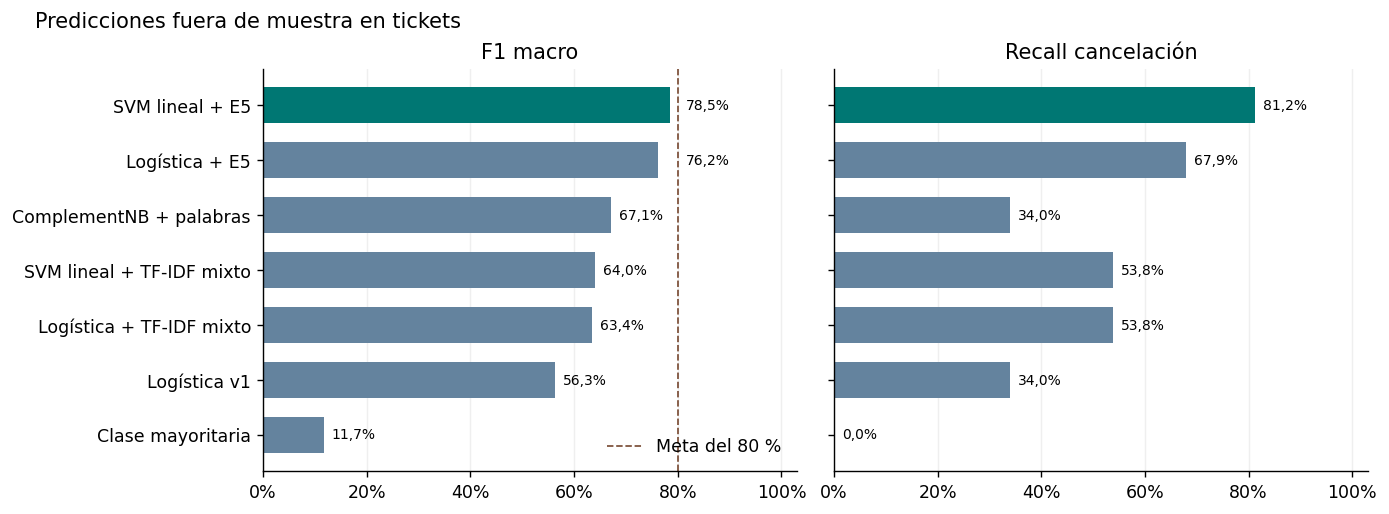

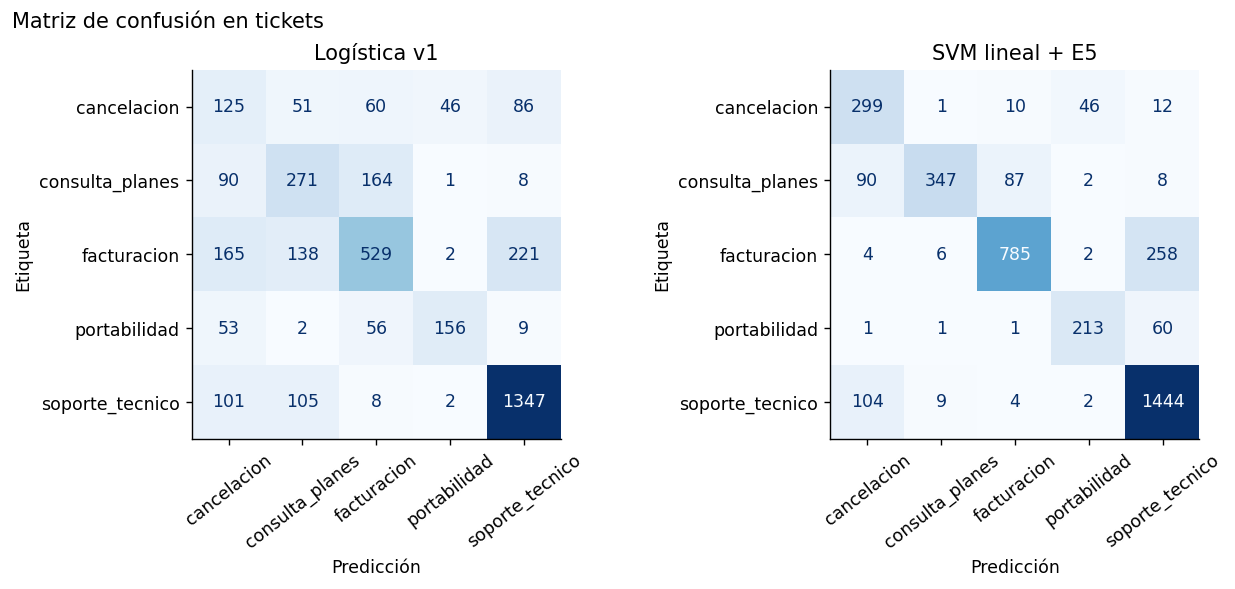

In [7]:
def class_results(actual, predictions_by_model):
    results = {}
    for name, predicted in predictions_by_model.items():
        report = classification_report(
            actual, predicted, labels=labels, output_dict=True, zero_division=0
        )
        table = pd.DataFrame(report).T.loc[labels, ["precision", "recall", "f1-score", "support"]]
        table["support"] = table["support"].astype(int)
        results[name] = table.rename(columns={
            "precision": "Precisión", "recall": "Recall", "f1-score": "F1", "support": "Filas"
        })
    return pd.concat(results, axis=1)

compared = list(dict.fromkeys([baseline, winner]))
display(class_results(y, {name: predictions[name] for name in compared}).round(3))
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True, layout="constrained")
for ax, metric in zip(axes, ("F1 macro", "Recall cancelación")):
    values = scores[metric].iloc[::-1]
    colors = ["#007773" if name == winner else "#64839e" for name in values.index]
    bars = ax.barh(values.index, values, color=colors, height=0.66)
    for bar, value in zip(bars, values):
        label_x = value + 0.015
        if metric == "F1 macro" and 0.72 < value < target_f1:
            label_x = target_f1 + 0.015
        ax.text(label_x, bar.get_y() + bar.get_height() / 2,
                f"{value:.1%}".replace(".", ","), va="center", fontsize=8)
    ax.set(xlim=(0, 1.03), title=metric)
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)
    if metric == "F1 macro":
        ax.axvline(target_f1, color="#7b4e37", linestyle="--", linewidth=1, label="Meta del 80 %")
        ax.legend(loc="lower right", frameon=False)
fig.suptitle("Predicciones fuera de muestra en tickets", x=0.02, ha="left")
plt.show()

def show_confusions(actual, predictions_by_model, title):
    count = len(predictions_by_model)
    fig, axes = plt.subplots(1, count, figsize=(5.1 * count, 4.6), squeeze=False, layout="constrained")
    for ax, (name, predicted) in zip(axes.flat, predictions_by_model.items()):
        ConfusionMatrixDisplay.from_predictions(
            actual, predicted, labels=labels, ax=ax, colorbar=False, cmap="Blues",
            xticks_rotation=38, values_format="d"
        )
        ax.set(title=name, xlabel="Predicción", ylabel="Etiqueta")
    fig.suptitle(title, x=0.02, ha="left")
    plt.show()

show_confusions(y, {name: predictions[name] for name in compared}, "Matriz de confusión en tickets")

## Evaluación en frases de clientes

Se usan las etiquetas del índice de transcripciones y la primera respuesta de `CLIENTE:` a la pregunta que abre el motivo de atención, identificada con las formulaciones del corpus sintético. Así se excluyen el saludo, la verificación de identidad, las intervenciones del asesor y los turnos posteriores. Cada uno de los dos modelos comparados en esta sección se ajusta con todos los tickets, tras fijar el ranking. Se cuentan las familias de frases y se calcula también F1 con el mismo peso por familia para comprobar cuánto influye la repetición.

Estas transcripciones son una verificación de transferencia dentro de los insumos de la prueba. Su soporte y diversidad son limitados y no incluyen Telegram.

50 transcripciones · 15 familias de frases · 0 familias exactas compartidas con tickets


canal,call_center,chat,whatsapp
categoria,,,
cancelacion,5,2,3
consulta_planes,9,0,1
facturacion,4,4,2
portabilidad,8,0,2
soporte_tecnico,8,2,0


,F1 macro,Recall cancelación,Precisión cancelación,Cancelaciones detectadas,Cancelaciones totales,F1 con igual peso por plantilla
Logística v1,0.793,0.9,1.0,9,10,0.801
SVM lineal + E5,0.917,1.0,1.0,10,10,0.931


Logística v1                     SVM lineal + E5         \
                   Precisión Recall     F1 Filas       Precisión Recall   
cancelacion            1.000    0.9  0.947    10           1.000    1.0   
consulta_planes        1.000    0.6  0.750    10           1.000    1.0   
facturacion            0.667    1.0  0.800    10           1.000    1.0   
portabilidad           1.000    0.5  0.667    10           1.000    0.6   
soporte_tecnico        0.667    1.0  0.800    10           0.714    1.0   

                              
                    F1 Filas  
cancelacion      1.000    10  
consulta_planes  1.000    10  
facturacion      1.000    10  
portabilidad     0.750    10  
soporte_tecnico  0.833    10

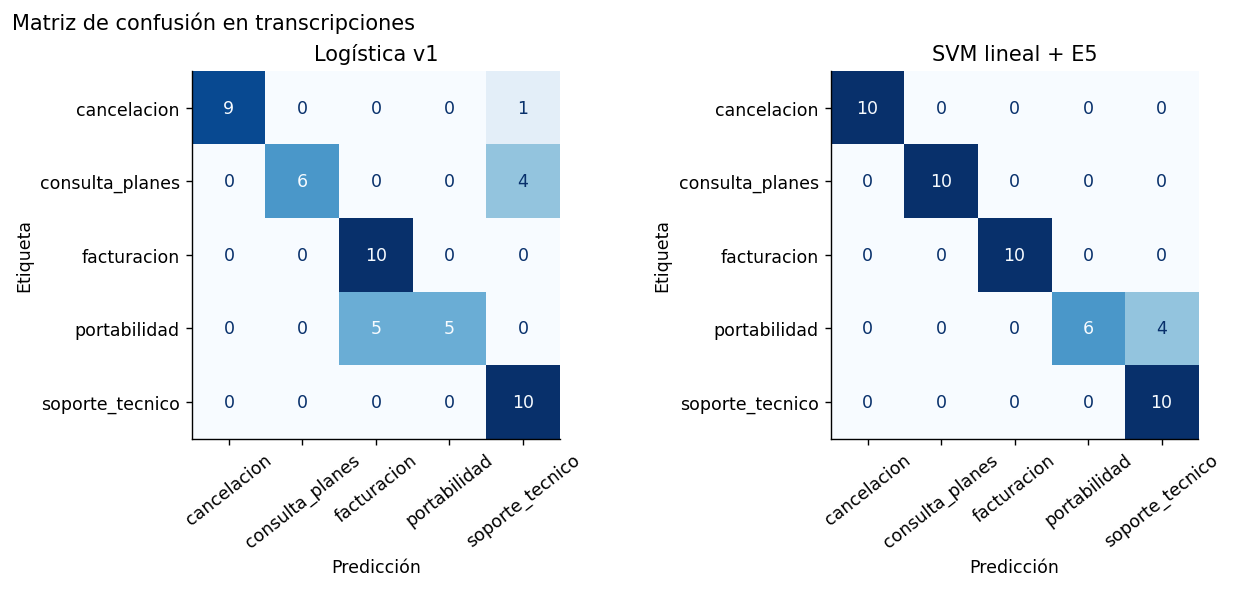

In [8]:
transcription_dir = insumos / "02_transcripciones"
index = pd.read_csv(transcription_dir / "indice_transcripciones.csv", encoding="utf-8-sig", dtype=str)
assert index["transcripcion_id"].is_unique and set(index["intencion"]) == LABELS

intake_question = re.compile(
    r"^(?:cuénteme\.|(?:cuénteme, |gracias\. )?¿en qué le "
    r"(?:ayudo|colaboro|puedo ayudar|puedo colaborar)(?: hoy)?\?)$"
)

def first_reason(transcript_id):
    path = transcription_dir / "llamadas" / f"{transcript_id}.txt"
    lines = path.read_text(encoding="utf-8-sig").splitlines()
    reasons = [
        normalize(reply.removeprefix("CLIENTE:").strip())
        for advisor, reply in zip(lines, lines[1:])
        if advisor.startswith("ASESOR:")
        and intake_question.fullmatch(normalize(advisor.removeprefix("ASESOR:")))
        and reply.startswith("CLIENTE:")
    ]
    if len(reasons) != 1 or not reasons[0]:
        raise ValueError(f"No se pudo identificar un único motivo de atención en {transcript_id}.")
    return reasons[0]

transcripts = index.rename(columns={"intencion": "categoria"}).copy()
transcripts["texto"] = transcripts["transcripcion_id"].map(first_reason)
transcripts["plantilla"] = transcripts["texto"].map(group)

transcript_features = {"texto": transcripts["texto"]}
if any(models[name][0] == "E5" for name in compared):
    transcript_features["E5"] = encode_texts(transcripts["texto"])
transfer_predictions = {}
with threadpool_limits(limits=2):
    for name in compared:
        representation, estimator = models[name]
        fitted = clone(estimator).fit(X[representation], y)
        transfer_predictions[name] = fitted.predict(transcript_features[representation])

conversation_y = transcripts["categoria"]
transfer = pd.DataFrame({
    name: {
        **metrics(conversation_y, pred),
        "F1 con igual peso por plantilla": group_weighted_f1(transcripts, pred),
    }
    for name, pred in transfer_predictions.items()
}).T
transfer[count_columns] = transfer[count_columns].astype(int)
print(
    f"{len(transcripts)} transcripciones · {transcripts['plantilla'].nunique()} familias de frases · "
    f"{len(set(tickets['plantilla']) & set(transcripts['plantilla']))} familias exactas compartidas con tickets"
)
display(transcripts.groupby(["categoria", "canal"]).size().unstack(fill_value=0))
display(transfer.round(3))
display(class_results(conversation_y, transfer_predictions).round(3))
show_confusions(conversation_y, transfer_predictions, "Matriz de confusión en transcripciones")

In [9]:
best = scores.loc[winner]
current = scores.loc[baseline]
external = transfer.loc[winner]
current_external = transfer.loc[baseline]

def decimal(value):
    return f"{value:.3f}".replace(".", ",")

def points(delta):
    return f"{delta * 100:+.1f}".replace(".", ",")

target_status = "alcanza" if best["F1 macro"] >= target_f1 else "queda por debajo de"
display(Markdown(
    f"**{winner}** obtuvo **{decimal(best['F1 macro'])} de F1 macro** en tickets "
    f"({points(best['F1 macro'] - current['F1 macro'])} puntos frente a v1) y un recall de "
    f"cancelación de **{decimal(best['Recall cancelación'])}** "
    f"({int(best['Cancelaciones detectadas'])}/{int(best['Cancelaciones totales'])}). "
    f"El resultado {target_status} la meta de {decimal(target_f1)}. "
    f"En transcripciones, el candidato obtuvo **{decimal(external['F1 macro'])} de F1 macro** "
    f"frente a **{decimal(current_external['F1 macro'])} de v1**, y reconoció "
    f"**{int(external['Cancelaciones detectadas'])}/{int(external['Cancelaciones totales'])} "
    f"cancelaciones**. En tickets, la precisión de cancelación fue "
    f"**{decimal(best['Precisión cancelación'])}** y el F1 macro del procedimiento "
    f"de selección anidado fue **{decimal(metrics(y, nested_predictions)['F1 macro'])}**."
))

**SVM lineal + E5** obtuvo **0,785 de F1 macro** en tickets (+22,2 puntos frente a v1) y un recall de cancelación de **0,812** (299/368). El resultado queda por debajo de la meta de 0,800. En transcripciones, el candidato obtuvo **0,917 de F1 macro** frente a **0,793 de v1**, y reconoció **10/10 cancelaciones**. En tickets, la precisión de cancelación fue **0,600** y el F1 macro del procedimiento de selección anidado fue **0,762**.

## Decisión y trabajo de datos

El candidato del ranking merece una validación con conversaciones más diversas antes de intervenir en el enrutamiento. Revisar primero las descripciones que comparten varias etiquetas, especialmente las de cancelación, y acordar una pauta para los motivos implícitos y las conversaciones con varias intenciones. Ampliar la muestra de primeros turnos reales anonimizados por canal y reservar familias completas para la validación.

Para una decisión operativa, medir precisión, recall y cobertura de cancelación con datos representativos y un umbral revisado. Medir también latencia y memoria de inferencia en el entorno del servicio. E5 añade un codificador y un artefacto de pesos. El modelo del servicio hoy devuelve un score a partir de `predict_proba`, mientras que `LinearSVC` entrega márgenes. Un candidato con SVM requiere definir y validar cómo se adapta ese contrato antes de registrarlo para serving.